In [102]:
!pip install tensorflow

In [103]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.typing import NDArray
from typing import Sequence, List, Tuple
from tensorflow.keras.datasets import mnist
from scipy.special import softmax
from collections.abc import Sequence
np.random.seed(42)

(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train = X_train.reshape(-1, 784) / 255.0
X_test = X_test.reshape(-1, 784) / 255.0

print(X_train.shape)
print(y_train.shape)

(60000, 784)
(60000,)


We use Xavier–Glorot weight initialization, defined by
$$
    W^{(i)} = \sqrt{\frac{6}{n^{(i+1)}+n^{(i)}}}
    \begin{bmatrix}
    Z_1 & \cdots & Z_{n^{(i)}}
    \end{bmatrix},
$$
where $Z_1,\ldots,Z_{n^{(i)}}$ are independent, identically distributed random vectors, each uniformly distributed on $[-1,1]^{n^{(i+1)}}$.

Whereas biases are initially set to $0$s.

In [104]:
class MultiLayerPerceptron:

    def __init__(
        self,
        sizes: List[int] | None = None,
    ) -> None:
        self.sizes: List[int] = [784, 30, 10] if sizes is None else sizes
        self.weights: List[NDArray[np.float64]] = [
            (6/(self.sizes[i + 1] + self.sizes[i]))**0.5 *
            (1 - 2 * np.random.rand(self.sizes[i + 1], self.sizes[i]))
            for i in range(len(self.sizes) - 1)
        ]
        self.biases: List[NDArray[np.float64]] = [
            np.zeros(self.sizes[i + 1])
            for i in range(len(self.sizes) - 1)
        ]
        self.memo_w: List[NDArray[np.float64]] = [
            np.zeros_like(w) for w in self.weights
        ]
        self.memo_b: List[NDArray[np.float64]] = [
            np.zeros_like(b) for b in self.biases
        ]


    def predict(
        self,
        x_mini_batch: NDArray[np.float64],
    ) -> NDArray[np.intp]:
        z = x_mini_batch

        for i in range(len(self.sizes) - 1):
            a = z @ self.weights[i].T + self.biases[i]
            z = np.tanh(a) if i < len(self.sizes) - 2 else softmax(a, axis=1)

        return np.argmax(z, axis=1)


    def forward(
        self,
        x_mini_batch: NDArray[np.float64],
        y_mini_batch: NDArray[np.uint8],
    ) -> Tuple[List[NDArray[np.float64]], float]:
        z = x_mini_batch
        activations = [z]

        for i in range(len(self.sizes) - 1):
            a = z @ self.weights[i].T + self.biases[i]
            z = np.tanh(a) if i < len(self.sizes) - 2 else softmax(a, axis=1)
            activations.append(z)

        probs = z[np.arange(len(y_mini_batch)), y_mini_batch]
        loss = np.mean(-np.log(probs + 1e-12))

        return activations, loss


    def backward(
        self,
        x_mini_batch: NDArray[np.float64],
        y_mini_batch: NDArray[np.uint8],
        activations: List[NDArray[np.float64]],
    ) -> Tuple[NDArray[np.float64]]:

        grads_w = [None] * (len(self.sizes) - 1)
        grads_b = [None] * (len(self.sizes) - 1)
        z = activations[len(self.sizes) - 1]
        delta = z.copy()
        delta[np.arange(len(y_mini_batch)), y_mini_batch] -= 1

        for i in range(len(self.sizes) - 2, -1, -1):
            grads_w[i] = delta.T @ activations[i]
            grads_b[i] = np.sum(delta, axis=0)

            if i > 0:
                delta = (
                    (delta @ self.weights[i]) *
                    (1 - activations[i] * activations[i])
                )

        return grads_w, grads_b


    def evaluate(self,
                 x_test: NDArray[np.float64],
                 y_test: NDArray[np.uint8],
                 batch_size: int,
    ) -> float:
        N = x_test.shape[0]
        ct = 0

        for i in range(0, N, batch_size):
            end = min(i + batch_size, N)
            x_batch = x_test[i: end]
            y_batch = y_test[i: end]
            ct += np.sum(self.predict(x_batch) == y_batch)

        return ct / N

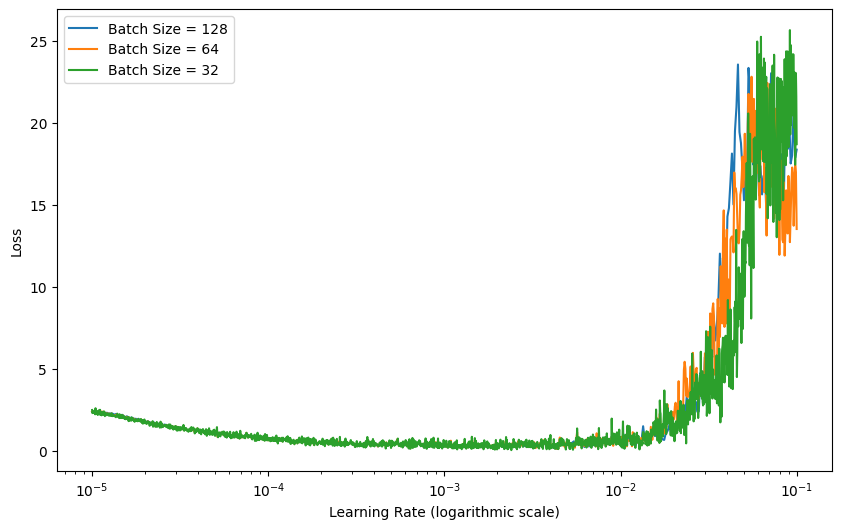

In [105]:
def run_lr_finder(network, x_train, y_train, batch_size, lr_start=1e-5, lr_end=1e-1, momentum=0.9):
    N = len(x_train)
    np.random.seed(42)
    idx = np.random.permutation(N)
    x_train = x_train[idx]
    y_train = y_train[idx]

    num_batches = (N + batch_size - 1) // batch_size
    learning_rates = np.logspace(np.log10(lr_start), np.log10(lr_end), num_batches)
    losses = []

    for batch_idx, lr in enumerate(learning_rates):
        start = batch_idx * batch_size
        end = min(start + batch_size, N)

        x_batch = x_train[start:end]
        y_batch = y_train[start:end]

        activations, loss = network.forward(x_batch, y_batch)
        losses.append(loss)
        grads_w, grads_b = network.backward(x_batch, y_batch, activations)

        for j in range(len(network.weights)):
            network.memo_w[j] = momentum * network.memo_w[j] + grads_w[j]
            network.memo_b[j] = momentum * network.memo_b[j] + grads_b[j]
            network.weights[j] -= lr * network.memo_w[j]
            network.biases[j] -= lr * network.memo_b[j]

    return learning_rates[:len(losses)], losses


np.random.seed(42)
model_128 = MultiLayerPerceptron()
lr_128, losses_128 = run_lr_finder(model_128, X_train, y_train, batch_size=128)

np.random.seed(42)
model_64 = MultiLayerPerceptron()
lr_64, losses_64 = run_lr_finder(model_64, X_train, y_train, batch_size=64)

np.random.seed(42)
model_32 = MultiLayerPerceptron()
lr_32, losses_32 = run_lr_finder(model_32, X_train, y_train, batch_size=32)

plt.figure(figsize=(10, 6))
plt.plot(lr_128, losses_128, label='Batch Size = 128')
plt.plot(lr_64, losses_64, label='Batch Size = 64')
plt.plot(lr_32, losses_32, label='Batch Size = 32')
plt.xscale('log')
plt.xlabel('Learning Rate (logarithmic scale)')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [106]:
def train_network(
    network: MultiLayerPerceptron,
    x_train: NDArray[np.float64],
    y_train: NDArray[np.uint8],
    x_test: NDArray[np.float64],
    y_test: NDArray[np.uint8],
    n_epochs: int = 1,
    batch_size: int = 64,
    lr: float = 1e-3,
    momentum: float = 0.85,
    l2_decay: float = 1e-5,
    plot = False,
):
    N = len(x_train)
    history_loss = []

    for epoch in range(1, n_epochs + 1):
        idx = np.random.permutation(N)
        x_train = x_train[idx]
        y_train = y_train[idx]

        running_loss = 0.0

        for i in range(0, N, batch_size):
            end = min(i + batch_size, N)
            x_batch = x_train[i:end]
            y_batch = y_train[i:end]

            activations, loss = network.forward(x_batch, y_batch)
            grads_w, grads_b = network.backward(x_batch, y_batch, activations)

            for j in range(len(network.sizes) - 2, -1, -1):
                network.memo_w[j] = (
                    momentum * network.memo_w[j] +
                    grads_w[j] +
                    2 * l2_decay * network.weights[j]
                )
                network.memo_b[j] = momentum * network.memo_b[j] + grads_b[j]
                network.weights[j] -= lr * network.memo_w[j]
                network.biases[j] -= lr * network.memo_b[j]

            running_loss += loss * len(x_batch)

        epoch_loss = running_loss / N
        history_loss.append(epoch_loss)

        accuracy = network.evaluate(x_test, y_test, batch_size)
        print(f"Epoch: {epoch}/{n_epochs} | Loss: {epoch_loss:.4f} | Accuracy: {100*accuracy:.2f}%")

    if plot:
        plt.figure(figsize=(10, 6))
        plt.plot(range(1, n_epochs + 1), history_loss, label="Training Loss")
        plt.title("Training Loss")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()

    print("\n")
    return accuracy

In [107]:
N = len(X_train)
np.random.seed(42)

idx = np.random.permutation(N)
split = int(0.8 * N)

X_train_tune = X_train[idx[:split]]
y_train_tune = y_train[idx[:split]]

X_test_tune = X_train[idx[split:]]
y_test_tune = y_train[idx[split:]]

In [108]:
for batch_size in [32, 64, 128]:
    print(f"Batch size: {batch_size}")
    accuracies = []

    for seed in [42, 43, 44, 45, 46]:
        np.random.seed(seed)
        network = MultiLayerPerceptron()
        accuracies.append(
            train_network(
              network,
              X_train_tune,
              y_train_tune,
              X_test_tune,
              y_test_tune,
              n_epochs=15,
              batch_size=batch_size,
            )
        )

    mean = sum(accuracies) / len(accuracies)
    std = (
        sum((acc - mean) * (acc - mean) for acc in accuracies) /
        (len(accuracies) - 1)
    ) ** 0.5
    print(
        (
            f"Average accuracy: {100*mean:.2f}% | "
            f"Standard deviation: {100*std:.2f}%"

        )
    )
    print("\n")

Batch size: 32
Epoch: 1/15 | Loss: 0.3189 | Accuracy: 93.81%
Epoch: 2/15 | Loss: 0.1850 | Accuracy: 94.58%
Epoch: 3/15 | Loss: 0.1496 | Accuracy: 94.98%
Epoch: 4/15 | Loss: 0.1289 | Accuracy: 95.78%
Epoch: 5/15 | Loss: 0.1146 | Accuracy: 95.68%
Epoch: 6/15 | Loss: 0.1045 | Accuracy: 95.95%
Epoch: 7/15 | Loss: 0.0949 | Accuracy: 95.96%
Epoch: 8/15 | Loss: 0.0889 | Accuracy: 95.69%
Epoch: 9/15 | Loss: 0.0816 | Accuracy: 95.95%
Epoch: 10/15 | Loss: 0.0768 | Accuracy: 95.73%
Epoch: 11/15 | Loss: 0.0726 | Accuracy: 96.03%
Epoch: 12/15 | Loss: 0.0686 | Accuracy: 95.84%
Epoch: 13/15 | Loss: 0.0638 | Accuracy: 96.03%
Epoch: 14/15 | Loss: 0.0594 | Accuracy: 96.10%
Epoch: 15/15 | Loss: 0.0583 | Accuracy: 95.84%


Epoch: 1/15 | Loss: 0.3160 | Accuracy: 93.17%
Epoch: 2/15 | Loss: 0.1804 | Accuracy: 94.73%
Epoch: 3/15 | Loss: 0.1454 | Accuracy: 95.43%
Epoch: 4/15 | Loss: 0.1263 | Accuracy: 95.23%
Epoch: 5/15 | Loss: 0.1130 | Accuracy: 95.63%
Epoch: 6/15 | Loss: 0.1031 | Accuracy: 95.56%
Epoch: 7/15

In [109]:
for momentum in [0.9, 0.8]:
    print(f"momentum: {momentum}")
    accuracies = []

    for seed in [42, 43, 44, 45, 46]:
        np.random.seed(seed)
        network = MultiLayerPerceptron()
        accuracies.append(
            train_network(
              network,
              X_train_tune,
              y_train_tune,
              X_test_tune,
              y_test_tune,
              n_epochs=15,
              momentum=momentum,
            )
        )

    mean = sum(accuracies) / len(accuracies)
    std = (
        sum((acc - mean) * (acc - mean) for acc in accuracies) /
        (len(accuracies) - 1)
    ) ** 0.5
    print(
        (
            f"Average accuracy: {100*mean:.2f}% | "
            f"Standard deviation: {100*std:.2f}%"
        )
    )
    print("\n")

momentum: 0.9
Epoch: 1/15 | Loss: 0.3110 | Accuracy: 93.98%
Epoch: 2/15 | Loss: 0.1815 | Accuracy: 94.77%
Epoch: 3/15 | Loss: 0.1503 | Accuracy: 94.95%
Epoch: 4/15 | Loss: 0.1318 | Accuracy: 95.33%
Epoch: 5/15 | Loss: 0.1169 | Accuracy: 95.04%
Epoch: 6/15 | Loss: 0.1052 | Accuracy: 95.68%
Epoch: 7/15 | Loss: 0.0961 | Accuracy: 95.64%
Epoch: 8/15 | Loss: 0.0923 | Accuracy: 95.71%
Epoch: 9/15 | Loss: 0.0849 | Accuracy: 95.43%
Epoch: 10/15 | Loss: 0.0790 | Accuracy: 95.84%
Epoch: 11/15 | Loss: 0.0740 | Accuracy: 95.63%
Epoch: 12/15 | Loss: 0.0714 | Accuracy: 95.47%
Epoch: 13/15 | Loss: 0.0658 | Accuracy: 95.50%
Epoch: 14/15 | Loss: 0.0636 | Accuracy: 95.65%
Epoch: 15/15 | Loss: 0.0593 | Accuracy: 95.60%


Epoch: 1/15 | Loss: 0.3080 | Accuracy: 93.61%
Epoch: 2/15 | Loss: 0.1782 | Accuracy: 94.24%
Epoch: 3/15 | Loss: 0.1453 | Accuracy: 95.38%
Epoch: 4/15 | Loss: 0.1277 | Accuracy: 95.20%
Epoch: 5/15 | Loss: 0.1160 | Accuracy: 95.48%
Epoch: 6/15 | Loss: 0.1064 | Accuracy: 95.43%
Epoch: 7/15 

In [110]:
for l2_decay in [1e-3, 1e-4]:
    print(f"l2 decay: {l2_decay}")
    accuracies = []

    for seed in [42, 43, 44, 45, 46]:
        np.random.seed(seed)
        network = MultiLayerPerceptron()
        accuracies.append(
            train_network(
              network,
              X_train_tune,
              y_train_tune,
              X_test_tune,
              y_test_tune,
              n_epochs=15,
              momentum=0.8,
              l2_decay=l2_decay,
            )
        )

    mean = sum(accuracies) / len(accuracies)
    std = (
        sum((acc - mean) * (acc - mean) for acc in accuracies) /
        (len(accuracies) - 1)
    ) ** 0.5
    print(
        (
            f"Average accuracy: {100*mean:.2f}% | "
            f"Standard deviation: {100*std:.2f}%"
        )
    )
    print("\n")

l2 decay: 0.001
Epoch: 1/15 | Loss: 0.3416 | Accuracy: 93.52%
Epoch: 2/15 | Loss: 0.1958 | Accuracy: 94.47%
Epoch: 3/15 | Loss: 0.1573 | Accuracy: 95.03%
Epoch: 4/15 | Loss: 0.1359 | Accuracy: 95.53%
Epoch: 5/15 | Loss: 0.1212 | Accuracy: 95.60%
Epoch: 6/15 | Loss: 0.1103 | Accuracy: 95.75%
Epoch: 7/15 | Loss: 0.1016 | Accuracy: 95.82%
Epoch: 8/15 | Loss: 0.0949 | Accuracy: 95.78%
Epoch: 9/15 | Loss: 0.0883 | Accuracy: 95.58%
Epoch: 10/15 | Loss: 0.0824 | Accuracy: 95.73%
Epoch: 11/15 | Loss: 0.0784 | Accuracy: 95.88%
Epoch: 12/15 | Loss: 0.0747 | Accuracy: 95.93%
Epoch: 13/15 | Loss: 0.0704 | Accuracy: 95.83%
Epoch: 14/15 | Loss: 0.0670 | Accuracy: 96.18%
Epoch: 15/15 | Loss: 0.0641 | Accuracy: 96.08%


Epoch: 1/15 | Loss: 0.3397 | Accuracy: 93.05%
Epoch: 2/15 | Loss: 0.1935 | Accuracy: 94.28%
Epoch: 3/15 | Loss: 0.1545 | Accuracy: 95.33%
Epoch: 4/15 | Loss: 0.1335 | Accuracy: 95.17%
Epoch: 5/15 | Loss: 0.1200 | Accuracy: 95.52%
Epoch: 6/15 | Loss: 0.1095 | Accuracy: 95.86%
Epoch: 7/1

Epoch: 1/50 | Loss: 0.3194 | Accuracy: 93.80%
Epoch: 2/50 | Loss: 0.1834 | Accuracy: 95.32%
Epoch: 3/50 | Loss: 0.1459 | Accuracy: 95.84%
Epoch: 4/50 | Loss: 0.1243 | Accuracy: 95.98%
Epoch: 5/50 | Loss: 0.1115 | Accuracy: 95.92%
Epoch: 6/50 | Loss: 0.1013 | Accuracy: 96.34%
Epoch: 7/50 | Loss: 0.0936 | Accuracy: 96.18%
Epoch: 8/50 | Loss: 0.0863 | Accuracy: 96.30%
Epoch: 9/50 | Loss: 0.0810 | Accuracy: 96.30%
Epoch: 10/50 | Loss: 0.0777 | Accuracy: 96.32%
Epoch: 11/50 | Loss: 0.0740 | Accuracy: 96.42%
Epoch: 12/50 | Loss: 0.0714 | Accuracy: 96.59%
Epoch: 13/50 | Loss: 0.0679 | Accuracy: 96.59%
Epoch: 14/50 | Loss: 0.0650 | Accuracy: 96.52%
Epoch: 15/50 | Loss: 0.0623 | Accuracy: 96.40%
Epoch: 16/50 | Loss: 0.0604 | Accuracy: 96.64%
Epoch: 17/50 | Loss: 0.0578 | Accuracy: 96.65%
Epoch: 18/50 | Loss: 0.0572 | Accuracy: 96.52%
Epoch: 19/50 | Loss: 0.0540 | Accuracy: 96.50%
Epoch: 20/50 | Loss: 0.0530 | Accuracy: 96.53%
Epoch: 21/50 | Loss: 0.0520 | Accuracy: 96.32%
Epoch: 22/50 | Loss: 0

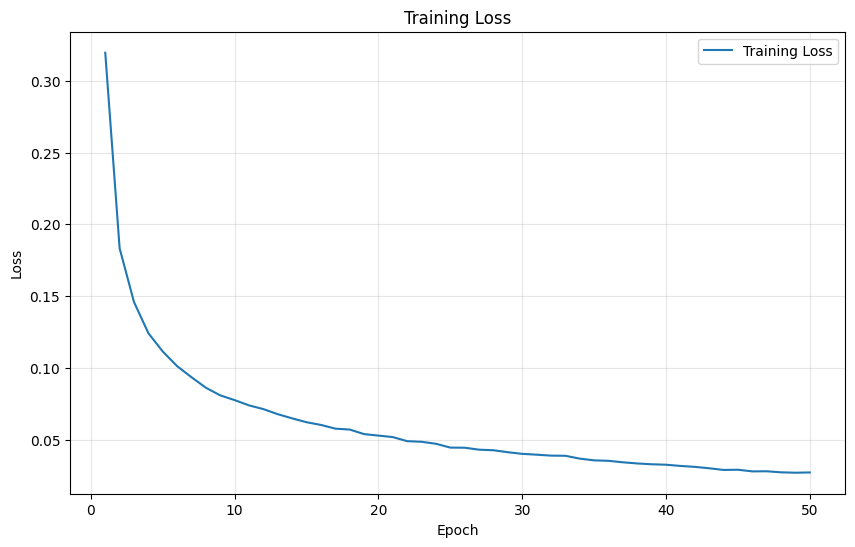

np.float64(0.9599)

In [112]:
np.random.seed(42)
network = MultiLayerPerceptron()
train_network(
    network,
    X_train,
    y_train,
    X_test,
    y_test,
    50,
    momentum=0.8,
    l2_decay=1e-3,
    plot=True,
)
